In [2]:
import pandas as pd
from matplotlib import pyplot as plt

df = pd.read_csv("../../data_sets/aust_fire/fire_archive_M6_96619.csv")
df["brightness"] = df["brightness"] - 273.15
df["bright_t31"] = df["bright_t31"] - 273.15
df.head()




,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-11.8070,142.0583,39.85,1.0,1.0,2019-08-01,56,Terra,MODIS,48,6.3,24.15,6.6,D,0
1,-11.7924,142.0850,46.15,1.0,1.0,2019-08-01,56,Terra,MODIS,71,6.3,24.15,11.3,D,0
2,-12.8398,132.8744,38.45,3.1,1.7,2019-08-01,57,Terra,MODIS,42,6.3,25.55,23.1,D,0
3,-14.4306,143.3035,36.95,1.1,1.1,2019-08-01,57,Terra,MODIS,33,6.3,22.95,6.5,D,0
4,-12.4953,131.4897,37.15,4.0,1.9,2019-08-01,57,Terra,MODIS,36,6.3,25.65,27.6,D,0


In [3]:
df.drop(columns="type",inplace=True)

/var/folders/4v/jnjs66z57js75njv0_934f0w0000gn/T/ipykernel_3833/3096871968.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns="type",inplace=True)


In [4]:
df["confidence"] = df["confidence"] / 100

In [5]:
df["observed_at"] = pd.to_datetime(
    df["acq_date"].astype(str)+
    " "+
    df["acq_time"].astype(str).str.zfill(4),
    format = "%Y-%m-%d %H%M",
    utc = False
)

df["observed_at"]

0       2019-08-01 00:56:00
1       2019-08-01 00:56:00
2       2019-08-01 00:57:00
3       2019-08-01 00:57:00
4       2019-08-01 00:57:00
                ...        
36006   2019-09-30 16:44:00
36007   2019-09-30 16:44:00
36008   2019-09-30 16:44:00
36009   2019-09-30 16:44:00
36010   2019-09-30 16:45:00
Name: observed_at, Length: 36011, dtype: datetime64[us]

In [6]:
df.drop(columns=["acq_date" , "acq_time"],inplace=True)

/var/folders/4v/jnjs66z57js75njv0_934f0w0000gn/T/ipykernel_3833/3146207012.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["acq_date" , "acq_time"],inplace=True)


In [7]:
(df.isnull().sum() / len(df)) * 100

latitude       0.0
longitude      0.0
brightness     0.0
scan           0.0
track          0.0
satellite      0.0
instrument     0.0
confidence     0.0
version        0.0
bright_t31     0.0
frp            0.0
daynight       0.0
observed_at    0.0
dtype: float64

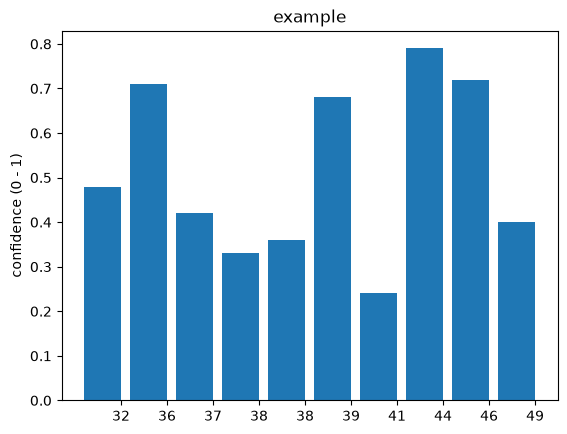

In [13]:
xs= [i + 0.1 for i,_ in enumerate(df["brightness"][:10])]

plt.bar(xs,df["confidence"][:10])

plt.ylabel("confidence (0 - 1)")
plt.title("example")

plt.xticks([i+0.5 for i,_ in enumerate(df["brightness"][:10])],sorted([int(x) for x in df["brightness"][:10]]))

plt.show()